In [1]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="llama3.2:latest")

print("Model is ready")

Model is ready


In [2]:
from langchain_community.tools import tool

@tool
def classify_email(email_content: str) -> str:
    """
    Classify email as Spam or Not Spam
    """

    spam_keywords = [
        "lottery",
        "winner",
        "free money",
        "click now",
        "claim reward",
        "offer"
    ]

    score = 0

    for word in spam_keywords:
        if word.lower() in email_content.lower():
            score += 1

    if score >= 2:
        return "Spam|0.95"

    elif score == 1:
        return "Spam|0.70"

    else:
        return "Not Spam|0.92"


ALL_TOOLS = [classify_email]

SENSITIVE_TOOLS = {"classify_email"}

print("Tools are ready")

Tools are ready


C:\Users\bg108836\AppData\Local\Temp\ipykernel_21716\4141351019.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import tool


In [4]:
from typing import TypedDict

from langchain_core.messages import AnyMessage
from typing import Annotated

from langgraph.graph.message import add_messages

class AgentState(TypedDict):

    messages: Annotated[list[AnyMessage], add_messages]


print("State is defined")

State is defined


In [5]:
from langgraph.types import Command, interrupt

from langchain_core.messages import (
    ToolMessage,
    SystemMessage
)

HITL_SYSTEM_PROMPT = SystemMessage(
    content=
    """
    You are an Email Spam Detection Agent.

    Whenever user provides an email,
    immediately call classify_email tool.

    Do not classify yourself.

    Always use the tool.
    """
)

model_with_tools = model.bind_tools(ALL_TOOLS)

In [6]:
def assistant_node(state: AgentState):

    response = model_with_tools.invoke(
        [HITL_SYSTEM_PROMPT] +
        state["messages"]
    )

    return {
        "messages": [response]
    }

In [7]:
def route_after_assistant_node(state):

    last_message = state["messages"][-1]

    tool_calls = getattr(
        last_message,
        "tool_calls",
        None
    )

    if not tool_calls:
        return "end_key"

    return "tools"

In [9]:
feedback_store = []

CONFIDENCE_THRESHOLD = 0.85
def human_review_node(state):

    last_tool_message = state["messages"][-1]

    output = last_tool_message.content

    prediction, confidence = output.split("|")

    confidence = float(confidence)

    if confidence >= CONFIDENCE_THRESHOLD:

        print(
            f"High Confidence ({confidence})"
        )

        feedback_store.append(
            {
                "prediction": prediction,
                "final_result": prediction
            }
        )

        return Command(
            goto="assistant_node"
        )

    decision = interrupt(
        {
            "question":
                "Approve or Correct Prediction",

            "ai_prediction":
                prediction,

            "confidence":
                confidence,

            "allowed_values":
                [
                    "Spam",
                    "Not Spam"
                ]
        }
    )

    feedback_store.append(
        {
            "prediction": prediction,
            "final_result": decision
        }
    )

    corrected_message = ToolMessage(
        content=
        f"Final Classification: {decision}",
        tool_call_id="review"
    )

    return Command(
        goto="assistant_node",
        update={
            "messages":
            [corrected_message]
        }
    )

In [10]:
from langgraph.prebuilt import ToolNode

tools_node = ToolNode(ALL_TOOLS)

print("Tool node ready")

Tool node ready


Nodes registered


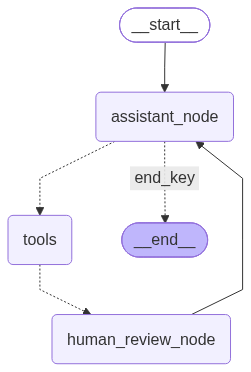

In [15]:
def route_after_tool(state):

    return "human_review_node"
from langgraph.graph import (
    StateGraph,
    START,
    END
)

from langgraph.checkpoint.memory import (
    MemorySaver
)

short_term_memory = MemorySaver()

graph_builder = StateGraph(
    AgentState
)
from langgraph.graph import (
    StateGraph,
    START,
    END
)

from langgraph.checkpoint.memory import (
    MemorySaver
)

short_term_memory = MemorySaver()

graph_builder = StateGraph(
    AgentState
)
graph_builder.add_node(
    "assistant_node",
    assistant_node
)

graph_builder.add_node(
    "tools",
    tools_node
)

graph_builder.add_node(
    "human_review_node",
    human_review_node
)

print("Nodes registered")
graph_builder.add_edge(
    START,
    "assistant_node"
)

graph_builder.add_conditional_edges(
    "assistant_node",
    route_after_assistant_node,
    {
        "tools": "tools",
        "end_key": END
    }
)

graph_builder.add_conditional_edges(
    "tools",
    route_after_tool,
    {
        "human_review_node":
            "human_review_node"
    }
)

graph_builder.add_edge(
    "human_review_node",
    "assistant_node"
)
graph = graph_builder.compile(
    checkpointer=short_term_memory
)

graph

In [17]:
hitl_config = {
    "configurable": {
        "thread_id":
            "email_session_1"
    }
}

response = graph.invoke(
    {
        "messages":
        [
            {
                "role": "user",
                "content":
                """
                Email:

                Dear Team,

                Meeting scheduled
                tomorrow at 10 AM.

                Regards
                Manager
                """
            }
        ]
    },
    hitl_config
)

print(response)

High Confidence (0.92)
{'messages': [HumanMessage(content='\n                Email:\n\n                Dear Team,\n\n                Meeting scheduled\n                tomorrow at 10 AM.\n\n                Regards\n                Manager\n                ', additional_kwargs={}, response_metadata={}, id='b1af3481-9d98-4ccf-8c41-1de8c5a629e3'), AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'llama3.2:latest', 'created_at': '2026-10-26T17:01:52.2780409Z', 'done': True, 'done_reason': 'stop', 'total_duration': 15832592800, 'load_duration': 6334978800, 'prompt_eval_count': 214, 'prompt_eval_duration': 5389651000, 'eval_count': 30, 'eval_duration': 4088546000, 'logprobs': None, 'model_name': 'llama3.2:latest', 'model_provider': 'ollama'}, id='lc_run--01a17929-0f38-71bf-ae1a-17b69df1da1e-0', tool_calls=[{'name': 'classify_email', 'args': {'email_content': 'Dear Team, Meeting scheduled tomorrow at 10 AM. Regards Manager'}, 'id': '4bab304e-b0d6-45c6-a1c8-1b33bbd0da21'

In [19]:
hitl_config = {
    "configurable": {
        "thread_id":
            "email_session_2"
    }
}

response = graph.invoke(
    {
        "messages":
        [
            {
                "role": "user",
                "content":
                """
                Congratulations!

                Click now and claim reward.

                Limited offer.
                """
            }
        ]
    },
    hitl_config
)

if "__interrupt__" in response:

    print(
        "Graph execution paused for human review"
    )

    print(
        response["__interrupt__"]
    )

High Confidence (0.95)


In [20]:
approve_command = Command(
    resume="Spam"
)

approval_response = graph.invoke(
    approve_command,
    hitl_config
)

print(approval_response)

{'messages': [HumanMessage(content='\n                Congratulations!\n\n                Click now and claim reward.\n\n                Limited offer.\n                ', additional_kwargs={}, response_metadata={}, id='c03b4d51-7bc8-4ca1-ae99-97b3f829a99d'), AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'llama3.2:latest', 'created_at': '2026-10-26T17:02:31.8090251Z', 'done': True, 'done_reason': 'stop', 'total_duration': 3832842400, 'load_duration': 41305800, 'prompt_eval_count': 204, 'prompt_eval_duration': 744782000, 'eval_count': 24, 'eval_duration': 3006759000, 'logprobs': None, 'model_name': 'llama3.2:latest', 'model_provider': 'ollama'}, id='lc_run--01a17929-d886-70de-8f65-db98526f896e-0', tool_calls=[{'name': 'classify_email', 'args': {'email_content': 'Congratulations! Click now and claim reward. Limited offer.'}, 'id': 'ccefae31-9eb0-4e27-a574-0e41d539a80d', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 204, 'output_to

In [21]:
correct_command = Command(
    resume="Not Spam"
)

correction_response = graph.invoke(
    correct_command,
    hitl_config
)

print(correction_response)

{'messages': [HumanMessage(content='\n                Congratulations!\n\n                Click now and claim reward.\n\n                Limited offer.\n                ', additional_kwargs={}, response_metadata={}, id='c03b4d51-7bc8-4ca1-ae99-97b3f829a99d'), AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'llama3.2:latest', 'created_at': '2026-10-26T17:02:31.8090251Z', 'done': True, 'done_reason': 'stop', 'total_duration': 3832842400, 'load_duration': 41305800, 'prompt_eval_count': 204, 'prompt_eval_duration': 744782000, 'eval_count': 24, 'eval_duration': 3006759000, 'logprobs': None, 'model_name': 'llama3.2:latest', 'model_provider': 'ollama'}, id='lc_run--01a17929-d886-70de-8f65-db98526f896e-0', tool_calls=[{'name': 'classify_email', 'args': {'email_content': 'Congratulations! Click now and claim reward. Limited offer.'}, 'id': 'ccefae31-9eb0-4e27-a574-0e41d539a80d', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 204, 'output_to

In [23]:
import pandas as pd

pd.DataFrame(feedback_store)

,prediction,final_result
0,Not Spam,Not Spam
1,Not Spam,Not Spam
2,Spam,Spam
3,Spam,Spam
